![Banner](../images/09_13_banner_rs_soil_moisture.png)

# SMAP L3 Enhanced: a Daily Cube and its Climatology

NASA's Soil Moisture Active Passive (SMAP) mission has measured L-band brightness temperature
since March 2015. Its radar failed after three months, but the radiometer has run ever since,
giving one of the most accurate global soil moisture records. The L3 Enhanced product
(SPL3SMP_E) grids each day's retrievals onto the 9 km EASE-Grid 2.0, using Backus-Gilbert
interpolation of the overlapping 36 km footprints. This notebook builds a ten-year daily cube over
Iowa and Nebraska from the AM and PM retrievals, applies the quality flags, counts what survives,
computes a smoothed day-of-year climatology, and uses it to show the 2023 drought as an anomaly.

## Overview

### The SMAP product family

| Product | Grid | Content |
|---|---|---|
| L2_SM_P, L3_SM_P (SPL3SMP) | 36 km | single channel retrieval from the radiometer footprint |
| L2_SM_P_E, L3_SM_P_E (SPL3SMP_E) | 9 km | the same retrieval on Backus-Gilbert interpolated Tb |
| L4_SM (SPL4SMGP) | 9 km, 3-hourly | Tb assimilated into a land surface model: surface and root zone |
| L2_SM_SP (SPL2SMAP_S) | 3 and 1 km | SMAP Tb disaggregated with Sentinel-1 backscatter |

### AM and PM overpasses

SMAP is in a sun-synchronous orbit with a 6 am local descending (AM) and 6 pm ascending (PM)
equator crossing. The baseline retrieval uses the AM pass, when the soil, canopy and air
temperatures are closest, so the single effective temperature of the model is most valid; the L3
file has both, and the PM group's variables end in `_pm`. The swath is 1,000 km wide, so a location
is seen two or three times in three days.

### Quality flags

`retrieval_qual_flag` (bits: 0 recommended quality, 1 retrieval attempted, 2 retrieval successful,
3 freeze-thaw retrieval successful; a set bit means "not") and `surface_flag` (static and radar
water, coastal, urban, precipitation, snow, frozen ground, mountains, dense vegetation) describe
each retrieval. The recommended quality mask keeps retrievals whose bit 0 is clear: vegetation
water content below 5 kg m-2, little open water and no frozen soil, among other conditions.

### Climatology and anomalies

Soil moisture has a strong seasonal cycle. The day-of-year climatology (the mean for each calendar
day, smoothed over a 31-day window) is the baseline against which droughts and wet spells are
anomalies: `anomaly = theta - climatology(doy)`.

## SMAP L3 Enhanced with GeoLattice

| Function | Purpose |
|---|---|
| `sd.smap_l3e()` (wraps `sm.open_product("SMAP_L3_E", ...)`) | ten-year cube over the Midwest box, cached |
| `sm.decode_flags` | named bit layers of `retrieval_qual_flag` and `surface_flag` |
| `sm.mask_quality` | recommended, all or strict quality |
| `sm.daily_cube` | AM first, PM fill, regular daily calendar |
| `sm.sm_climatology`, `sm.sm_anomaly` | smoothed day-of-year climatology and anomalies |

### Learning objectives

1. Read SMAP L3 Enhanced retrievals with their ancillary layers for a region and ten years.
2. Decode the quality bits and see which conditions remove data in each season.
3. Build a daily cube from the AM and PM overpasses and measure the revisit.
4. Compute a smoothed day-of-year climatology and monthly climatology maps.
5. Map and plot the 2023 drought as anomalies.

### Data

| Dataset | Content |
|---|---|
| SMAP L3 Enhanced (SPL3SMP_E v006), 31 March 2015 to 31 December 2025 | 9 km AM and PM soil moisture, quality and surface flags, VWC, vegetation opacity, surface temperature and Tb; 101 W to 90 W, 40 N to 44 N |

### Contents

- Setup
- What is in the cube
- Quality flags through the year
- A daily cube from two overpasses
- Day-of-year climatology
- The 2023 drought as an anomaly
- Summary and exercises

## Setup

In [1]:
import warnings  # warning control
warnings.filterwarnings("ignore")  # hide routine library warnings
from pathlib import Path  # file paths

import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import pandas as pd  # tables
import rioxarray  # noqa: F401  (registers the .rio accessor)
import xarray as xr  # labelled rasters

import geolattice  # GeoLattice
import geolattice.rsense.soil_moisture as sm  # soil moisture physics, products, retrieval and validation
import sm_data as sd  # chapter helper: subsets, downloads and caches the data

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
OUT = Path("outputs")  # results written by this chapter
OUT.mkdir(exist_ok=True)  # create it if needed
print("GeoLattice", geolattice.__version__, "| data folder", sd.DATA.relative_to(sd.DATA.parents[3]))  # versions and paths

raw = sd.smap_l3e()  # cached SPL3SMP_E cube, AM and PM
iowa = sd.ease2_clip(raw, sd.IOWA_REGION)  # Iowa and its neighbours (97 W to 90 W)
print(raw)  # dimensions and variables

GeoLattice 0.3.49 | data folder GeoLattice/Data/08_remote_sensing/08_13_soil_moisture


<xarray.Dataset> Size: 1GB
Dimensions:                   (time: 3845, overpass: 2, y: 43, x: 119)
Coordinates:
  * time                      (time) datetime64[ns] 31kB 2015-03-31 ... 2025-...
  * overpass                  (overpass) <U2 16B 'AM' 'PM'
  * y                         (y) float64 344B 5.085e+06 5.076e+06 ... 4.707e+06
    row                       (y) int64 344B 247 248 249 250 ... 286 287 288 289
  * x                         (x) float64 952B -9.742e+06 ... -8.679e+06
    col                       (x) int64 952B 846 847 848 849 ... 961 962 963 964
    lat                       (y, x) float64 41kB 43.96 43.96 ... 40.0 40.0
    lon                       (y, x) float64 41kB -101.0 -100.9 ... -89.95
    spatial_ref               int64 8B 0
Data variables:
    sm                        (time, overpass, y, x) float32 157MB nan ... 0....
    retrieval_qual_flag       (time, overpass, y, x) uint16 79MB 7 7 7 ... 0 0 0
    surface_flag              (time, overpass, y, x) uint16 79M

## What is in the cube

In [2]:
info = pd.DataFrame({v: {"dims": ", ".join(raw[v].dims), "dtype": str(raw[v].dtype),
                         "AM mean": float(raw[v].sel(overpass="AM").where(raw[v].sel(overpass="AM") < 65534).mean())}
                     for v in raw.data_vars}).T  # one row per variable
display(info)  # variables of the retrieval
print(f"{raw.sizes['time']} days, {raw.sizes['y']} x {raw.sizes['x']} cells of 9 km, "
      f"{raw.nbytes / 2**20:.0f} MB in memory")  # size

,dims,dtype,AM mean
sm,"time, overpass, y, x",float32,0.205963
retrieval_qual_flag,"time, overpass, y, x",uint16,4.205857
surface_flag,"time, overpass, y, x",uint16,1044.25647
vegetation_water_content,"time, overpass, y, x",float32,1.701045
vegetation_opacity,"time, overpass, y, x",float32,0.230567
surface_temperature,"time, overpass, y, x",float32,285.129211
tb_v_corrected,"time, overpass, y, x",float32,255.486008
tb_h_corrected,"time, overpass, y, x",float32,234.927811


3845 days, 43 x 119 cells of 9 km, 1051 MB in memory


## Quality flags through the year

,"in swath, retrieval attempted",not recommended,frozen (radiometer),snow or ice,precipitation,static water
1,11.0,29.0,18.0,18.0,2.0,3.0
2,18.0,23.0,8.0,11.0,0.0,3.0
3,42.0,24.0,4.0,6.0,3.0,3.0
4,49.0,21.0,3.0,1.0,4.0,3.0
5,48.0,27.0,3.0,0.0,5.0,3.0
6,49.0,20.0,1.0,0.0,4.0,3.0
7,49.0,14.0,0.0,0.0,3.0,3.0
8,51.0,14.0,0.0,0.0,3.0,3.0
9,49.0,14.0,1.0,0.0,2.0,3.0
10,51.0,20.0,7.0,1.0,2.0,3.0


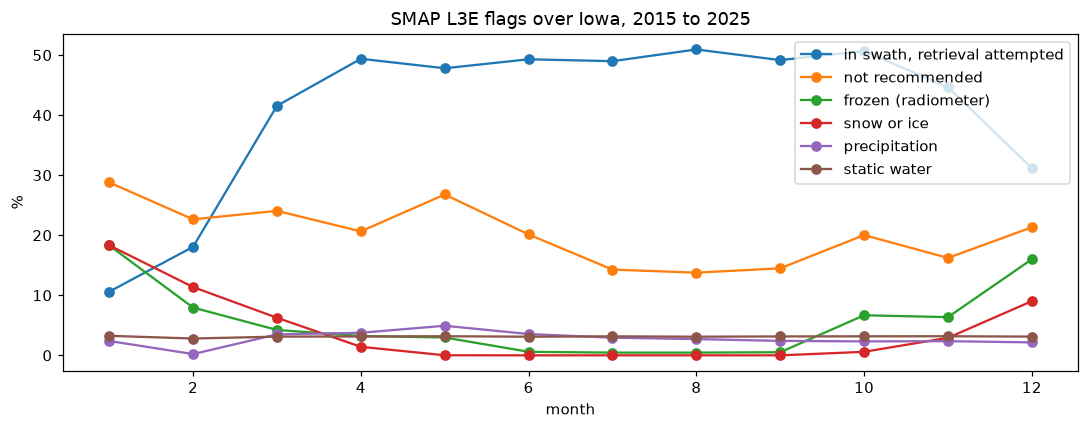

In [3]:
q = sm.decode_flags(iowa.retrieval_qual_flag.sel(overpass="AM"), "SMAP")  # retrieval bits
s = sm.decode_flags(iowa.surface_flag.sel(overpass="AM"), "SMAP_SURFACE")  # surface bits
attempted = ~q.retrieval_not_attempted & (iowa.retrieval_qual_flag.sel(overpass="AM") < 65534)  # cells in the swath with a retrieval attempt
month = iowa.time.dt.month  # calendar month
share = pd.DataFrame({
    "in swath, retrieval attempted": attempted.groupby(month).mean(...).values,
    "not recommended": q.not_recommended.where(attempted).groupby(month).mean(...).values,
    "frozen (radiometer)": s.frozen_radiometer.where(attempted).groupby(month).mean(...).values,
    "snow or ice": s.snow_ice.where(attempted).groupby(month).mean(...).values,
    "precipitation": s.precipitation.where(attempted).groupby(month).mean(...).values,
    "static water": s.static_water.where(attempted).groupby(month).mean(...).values,
}, index=range(1, 13)) * 100  # percent of AM cells (first column) and of attempted retrievals (others)
display(share.round(0))  # table
ax = share.plot(figsize=(10, 4), marker="o"); ax.set_xlabel("month"); ax.set_ylabel("%")  # plot
ax.set_title("SMAP L3E flags over Iowa, 2015 to 2025"); plt.tight_layout(); plt.show()  # draw

The AM swath covers about half of the region on a given day; in winter far fewer cells get a
retrieval attempt (11 % in January), because the retrieval is skipped over frozen ground and snow. Of
the attempted retrievals, 14 to 29 % are not of recommended quality depending on the month (mostly
cells with towns, lakes or, in winter, snow); the radiometer flags frozen ground in 18 % of January
retrievals and almost none in summer; precipitation at overpass time flags 2 to 5 %, static water 3 %.

## A daily cube from two overpasses

May to September: 51% of cells retrieved on an average day; 87 days of 153 per cell and season (median)
retrievals from the PM pass: 25%


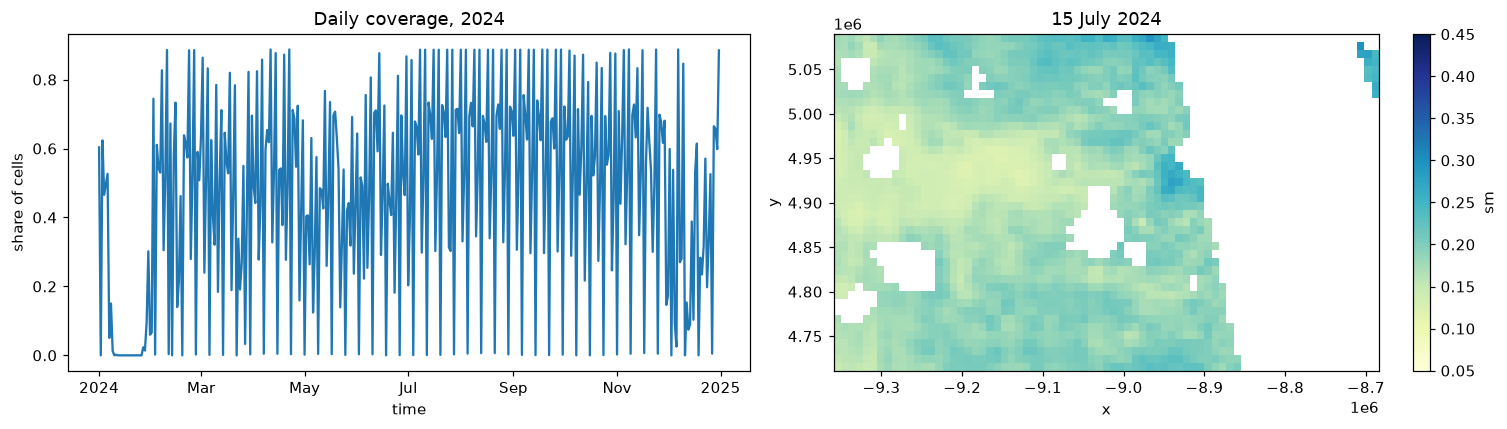

In [4]:
good = sm.mask_quality(iowa, level="recommended")  # recommended quality, no frozen or water cells
cube = sm.daily_cube(good, combine="am_first")  # AM first, PM where AM is missing
sm_ = cube.sm  # daily soil moisture
cover = sm_.notnull().mean(("y", "x"))  # fraction of the region with a retrieval each day
season = cover.where(cover.time.dt.month.isin([5, 6, 7, 8, 9]))  # growing season
gap = sm_.where(sm_.time.dt.month.isin([5, 6, 7, 8, 9])).notnull()  # observed or not, May to September
revisit = gap.sum("time") / gap.time.dt.year.to_series().nunique()  # observed days per season and cell
print(f"May to September: {float(season.mean()):.0%} of cells retrieved on an average day; "
      f"{float(revisit.median()):.0f} days of 153 per cell and season (median)")  # revisit
used = cube.overpass_used.where(cube.overpass_used >= 0)  # 0 AM, 1 PM
print(f"retrievals from the PM pass: {float((used == 1).sum() / used.notnull().sum()):.0%}")  # share filled by PM
fig, ax = plt.subplots(1, 2, figsize=(14, 4))  # coverage and one day
cover.sel(time="2024").plot(ax=ax[0]); ax[0].set_ylabel("share of cells"); ax[0].set_title("Daily coverage, 2024")  # coverage series
sm_.sel(time="2024-07-15").plot(ax=ax[1], vmin=0.05, vmax=0.45, cmap="YlGnBu"); ax[1].set_title("15 July 2024")  # one map
plt.tight_layout(); plt.show()  # draw

From May to September 51 % of the region has a recommended retrieval on an average day, and a
typical cell has one on 87 of the 153 days of the season; the evening pass contributes a quarter of
the cube. The map shows swath edges and the east-west soil moisture gradient that follows rainfall.

## Day-of-year climatology

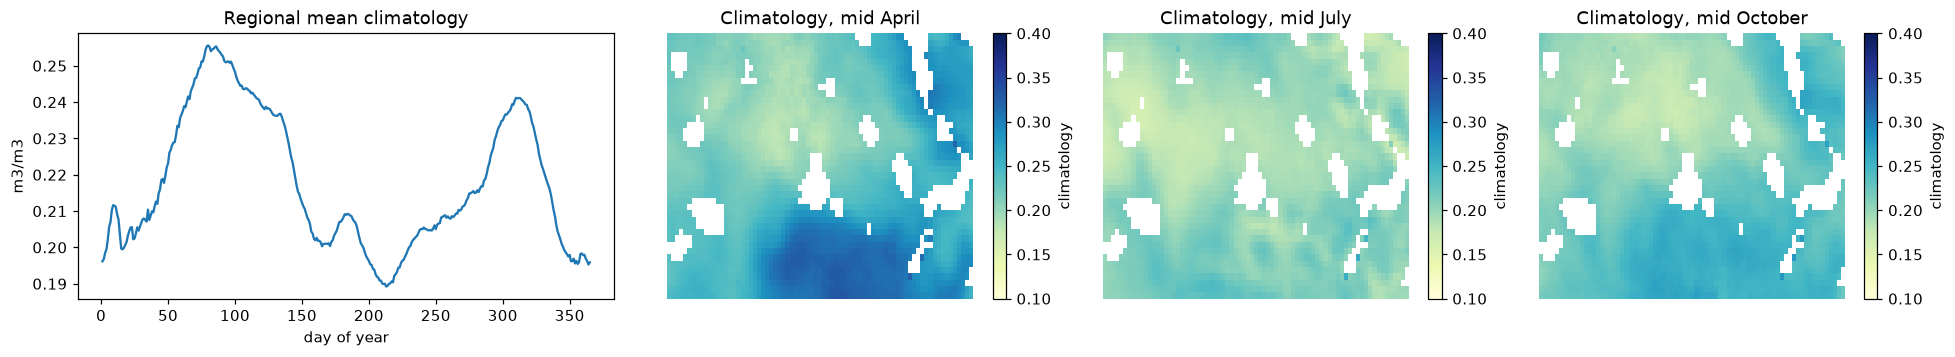

wettest day of year 80 (0.256), driest 213 (0.189)


In [5]:
clim = sm.sm_climatology(sm_, window=31, period=("2015-04-01", "2025-12-31"))  # smoothed day-of-year mean
mean_curve = clim.mean(("y", "x")).to_series()  # regional climatology
fig, ax = plt.subplots(1, 4, figsize=(18, 3.5), gridspec_kw={"width_ratios": [1.4, 1, 1, 1]})  # curve and three months
ax[0].plot(mean_curve.index, mean_curve.values); ax[0].set_xlabel("day of year"); ax[0].set_ylabel("m3/m3")  # seasonal cycle
ax[0].set_title("Regional mean climatology")  # title
for a, (doy, name) in zip(ax[1:], ((105, "mid April"), (196, "mid July"), (288, "mid October"))):  # three months
    clim.sel(doy=doy).plot(ax=a, vmin=0.1, vmax=0.4, cmap="YlGnBu"); a.set_title(f"Climatology, {name}"); a.axis("off")  # maps
plt.tight_layout(); plt.show()  # draw
print(f"wettest day of year {int(mean_curve.idxmax())} ({mean_curve.max():.3f}), driest {int(mean_curve.idxmin())} ({mean_curve.min():.3f})")  # extremes
clim.to_netcdf(OUT / "smap_l3e_climatology_iowa.nc")  # save for later notebooks

The regional mean peaks at about 0.26 m3 m-3 around day 80 (late March), after snowmelt and spring
rain, and reaches its minimum of about 0.19 at day 213 (early August), when the crops transpire most.
The east is wetter than the west, following the rainfall gradient across the Great Plains.

## The 2023 drought as an anomaly

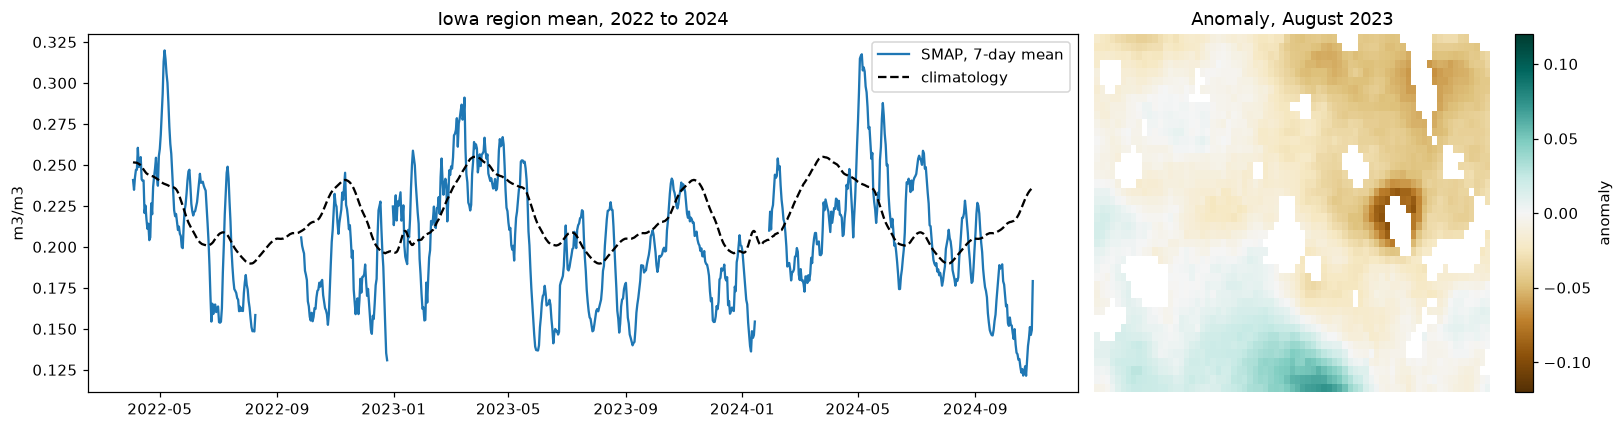

year,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
June to August anomaly (m3/m3),0.027,-0.002,-0.016,0.004,0.017,-0.015,-0.012,-0.009,-0.02,0.009,0.013


In [6]:
anom = sm.sm_anomaly(sm_, clim=clim)  # theta minus the climatology of the same day
reg = pd.DataFrame({"soil moisture": sm_.mean(("y", "x")).to_series(), "climatology": None})  # regional means
doy = np.minimum(reg.index.dayofyear, 365)  # day of year
reg["climatology"] = mean_curve.reindex(doy).values  # regional climatology on each date
fig, ax = plt.subplots(1, 2, figsize=(15, 4), gridspec_kw={"width_ratios": [2, 1]})  # series and map
r = reg.loc["2022-04":"2024-10"].rolling(7, min_periods=3).mean()  # weekly smoothing
ax[0].plot(r.index, r["soil moisture"], label="SMAP, 7-day mean"); ax[0].plot(r.index, r["climatology"], "k--", label="climatology")  # series
ax[0].legend(); ax[0].set_ylabel("m3/m3"); ax[0].set_title("Iowa region mean, 2022 to 2024")  # labels
aug = anom.sel(time=slice("2023-08-01", "2023-08-31")).mean("time")  # August 2023 mean anomaly
aug.plot(ax=ax[1], cmap="BrBG", vmin=-0.12, vmax=0.12); ax[1].set_title("Anomaly, August 2023"); ax[1].axis("off")  # map
plt.tight_layout(); plt.show()  # draw
yearly = anom.where(anom.time.dt.month.isin([6, 7, 8])).groupby("time.year").mean(...).to_series()  # summer anomaly per year
display(yearly.rename("June to August anomaly (m3/m3)").to_frame().T.round(3))  # table

The table ranks the summers. 2023 had the most negative June to August anomaly of the decade
(-0.020 m3 m-3), followed by 2017, 2020 and 2021; 2015 and 2019 were the wettest. In 2023 soil
moisture stayed below the climatology from early summer to autumn across most of the region. Notebook 25 turns these anomalies into percentiles and
drought classes.

## Summary and exercises

- SMAP L3 Enhanced over the Midwest box is a cube of about 3,900 days of AM and PM retrievals with
  their flags and ancillary layers.
- Winter retrievals are few (frozen ground, snow); 14 to 29 % of attempted retrievals are not of
  recommended quality.
- With AM first and PM fill, about half of the region has a retrieval on a summer day, and a cell has
  one on 87 of 153 days of the season.
- The smoothed climatology peaks in late March (0.26 m3 m-3) and bottoms out in early August (0.19);
  2023 was the driest summer of the record.

**Exercises**

1. Use `combine="mean"` in `sm.daily_cube`. Where do the AM and PM retrievals differ most, and in
   which season?
2. Apply `level="strict"` in `sm.mask_quality`. How many more retrievals are removed, and is the 2023
   anomaly different?
3. Plot the vegetation water content (`vegetation_water_content`) climatology for July. Which
   parts of the region exceed 5 kg m-2?
4. Compute the climatology from 2015 to 2020 only and recompute the 2023 anomaly. How sensitive is
   an anomaly to the reference period?